## 1. Import thư viện

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

## 2. Cấu hình đường dẫn và đọc các tệp TSV

In [2]:
path_train = Path("../data/raw/en-nn-train.tsv")
df_train = pd.read_csv(path_train, sep="\t", header=0, quoting=3, encoding="utf-8")

In [83]:
path_trial = Path("../dataset/en-nn-trial.tsv")
df_trial = pd.read_csv(path_trial, sep="\t", header=0, quoting=3, encoding="utf-8")

In [84]:
df = pd.concat([df_train, df_trial], ignore_index=True)

## 3. Kiểm tra nhanh dữ liệu

In [3]:
df_train.tail(15)

,ContextID,Compound,Mod,Head,ModAvg,ModStd,HeadAvg,HeadStd,Context
3465,13466,yield point,yield,point,2.8,2.149940,2.4,2.17051,"Being thixotropic, solder pastes also have a y..."
3466,13467,yield point,yield,point,3.7,1.828780,2.6,1.50555,There is so little deflection in a properly ma...
3467,13468,yield point,yield,point,2.9,1.791960,2.8,2.04396,"For the purpose of these specifications, the y..."
3468,13469,yield point,yield,point,2.2,2.250930,3.2,1.87380,The yield point is well marked in iron and mil...
3469,13470,yield point,yield,point,3.0,2.108190,3.2,2.29976,"If there is no demand on any other phase, the ..."
3470,13471,zinc plate,zinc,plate,3.1,2.469820,1.1,1.44914,"""The Smee cell is a zinc plate side by side wi..."
3471,13472,zinc plate,zinc,plate,4.4,0.699206,2.5,1.64992,"""It bites because the term """" aqua fortis """" w..."
3472,13473,zinc plate,zinc,plate,3.2,2.097620,2.5,2.46080,I like letterpress at it 's purest form ' desi...
3473,13474,zinc plate,zinc,plate,3.6,2.065590,2.6,2.11870,"The zinc plate being immersed in the acid, and..."
3474,13475,zinc plate,zinc,plate,4.4,0.843274,2.9,2.33095,"And this current may be so intense, if the aci..."


In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3490 entries, 0 to 3489
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ContextID  3490 non-null   int64  
 1   Compound   3490 non-null   object 
 2   Mod        3490 non-null   object 
 3   Head       3490 non-null   object 
 4   ModAvg     3490 non-null   float64
 5   ModStd     3490 non-null   float64
 6   HeadAvg    3490 non-null   float64
 7   HeadStd    3490 non-null   float64
 8   Context    3490 non-null   object 
dtypes: float64(4), int64(1), object(4)
memory usage: 245.5+ KB


In [89]:
df.describe(include="all")

,ContextID,Compound,Mod,Head,ModAvg,ModStd,HeadAvg,HeadStd,Context
count,3490.000000,3490,3490,3490,3490.000000,3490.000000,3490.000000,3490.000000,3490
unique,NaN,446,313,88,NaN,NaN,NaN,NaN,3486
top,NaN,zinc plate,family,house,NaN,NaN,NaN,NaN,"It consists of a small glass cell, containing ..."
freq,NaN,10,90,140,NaN,NaN,NaN,NaN,2
mean,11732.663324,NaN,NaN,NaN,3.659830,1.439229,3.912297,1.313424,NaN
std,1013.890869,NaN,NaN,NaN,0.996548,0.577640,0.886763,0.627506,NaN
min,9001.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,NaN
25%,10863.250000,NaN,NaN,NaN,3.200000,1.059350,3.400000,0.707107,NaN
50%,11735.500000,NaN,NaN,NaN,3.900000,1.577620,4.100000,1.475730,NaN
75%,12607.750000,NaN,NaN,NaN,4.400000,1.885620,4.600000,1.825740,NaN


In [90]:
df.shape

(3490, 9)

## 4. Kiểm tra dữ liệu thiếu, trùng lặp

In [91]:
df.isnull().sum()

ContextID    0
Compound     0
Mod          0
Head         0
ModAvg       0
ModStd       0
HeadAvg      0
HeadStd      0
Context      0
dtype: int64

In [92]:
duplicates = df[df.duplicated(subset=['Compound', 'Context'], keep=False)]
print(duplicates)

Empty DataFrame
Columns: [ContextID, Compound, Mod, Head, ModAvg, ModStd, HeadAvg, HeadStd, Context]
Index: []


## 5. Phân phối điểm người gán nhãn (`Avg`, `Std`)

`Avg` là điểm trung bình của người gán nhãn cho **một câu/ngữ cảnh**. `Std` mô tả mức phân tán đánh giá của người gán nhãn cho câu đó. `Std` không giống với độ lệch chuẩn của `Avg` giữa nhiều ngữ cảnh của cùng một target.

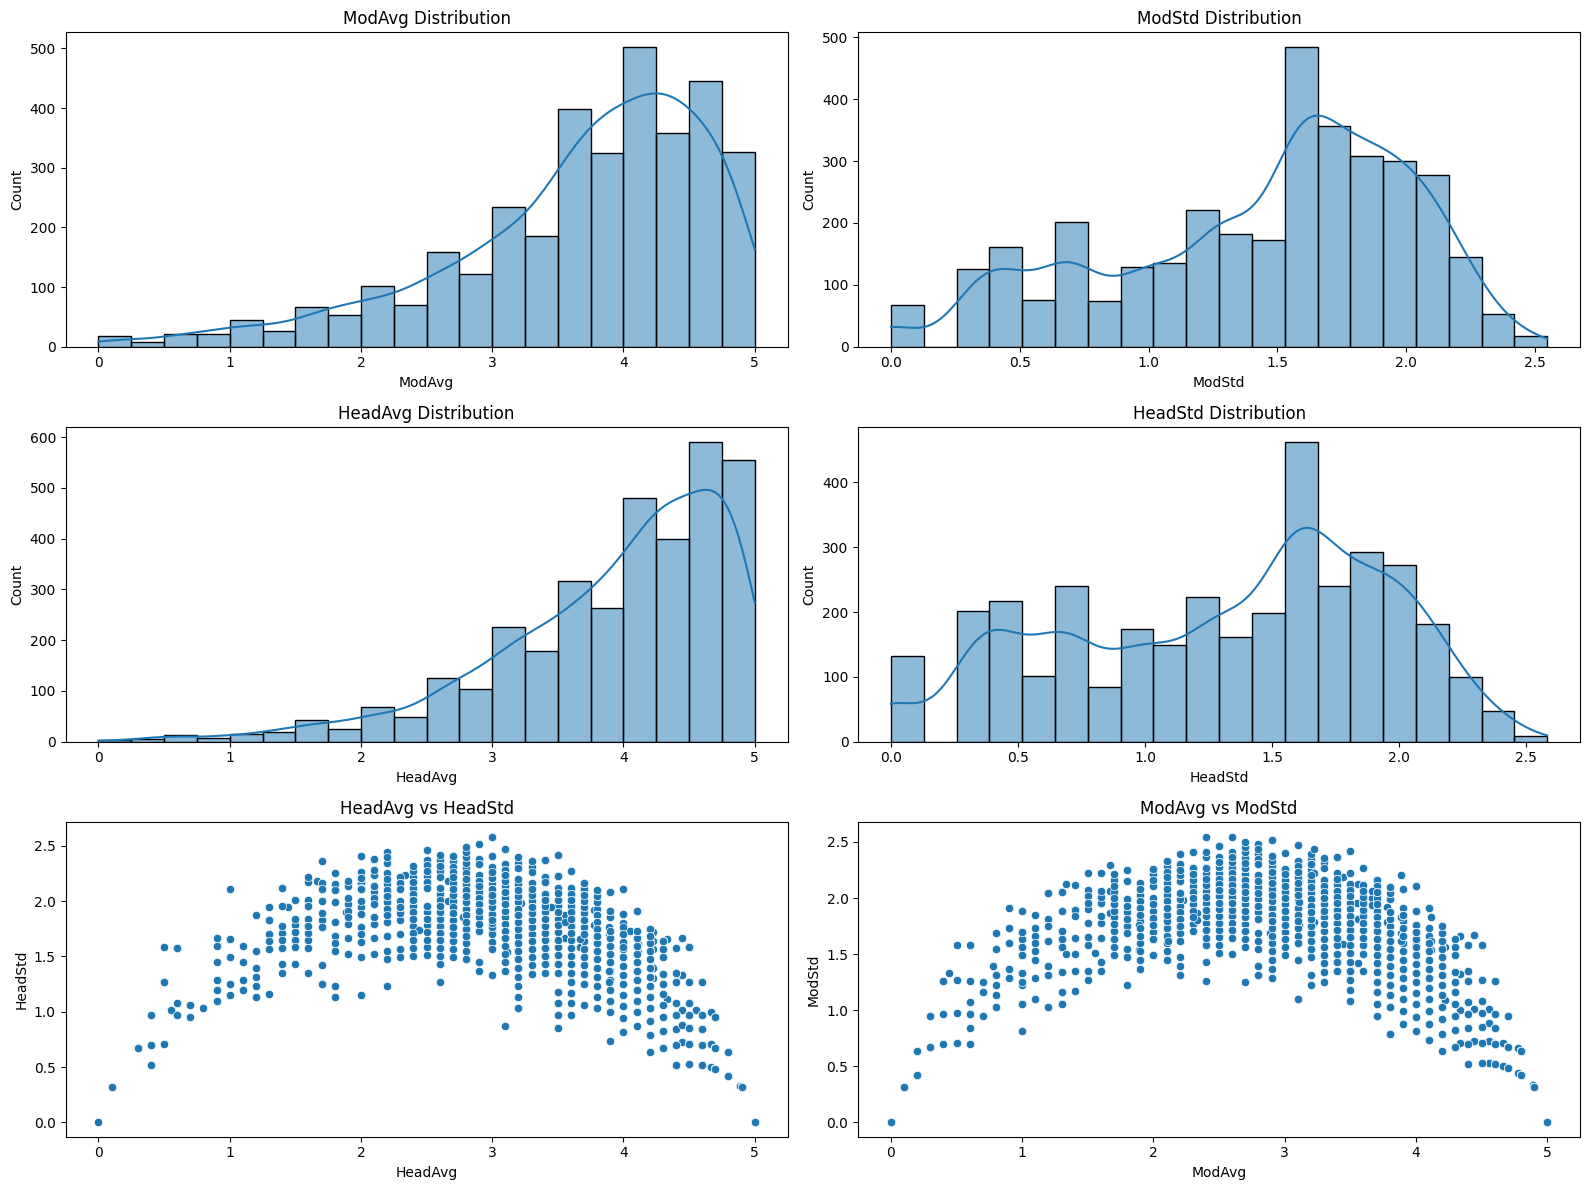

In [93]:
fig, axes = plt.subplots(3, 2, figsize=(16, 12))

sns.histplot(data=df, x='ModAvg', bins=20, kde=True, ax=axes[0, 0])
axes[0, 0].set_title('ModAvg Distribution')

sns.histplot(data=df, x='ModStd', bins=20, kde=True, ax=axes[0, 1])
axes[0, 1].set_title('ModStd Distribution')

sns.histplot(data=df, x='HeadAvg', bins=20, kde=True, ax=axes[1, 0])
axes[1, 0].set_title('HeadAvg Distribution')

sns.histplot(data=df, x='HeadStd', bins=20, kde=True, ax=axes[1, 1])
axes[1, 1].set_title('HeadStd Distribution')

sns.scatterplot(data=df, x='HeadAvg', y='HeadStd', ax=axes[2, 0])
axes[2, 0].set_title('HeadAvg vs HeadStd')

sns.scatterplot(data=df, x='ModAvg', y='ModStd', ax=axes[2, 1])
axes[2, 1].set_title('ModAvg vs ModStd')

plt.tight_layout()
plt.show()

## 6. Những noun compound và tần suất xuất hiện

In [94]:
print(df['Compound'].value_counts())

Compound
zinc plate             10
account book           10
winter temperature     10
wedding ring           10
wedding party          10
                       ..
ticket barrier          5
potash solution         4
hydrogen scale          3
comparison spectrum     3
viscosity work          1
Name: count, Length: 446, dtype: int64


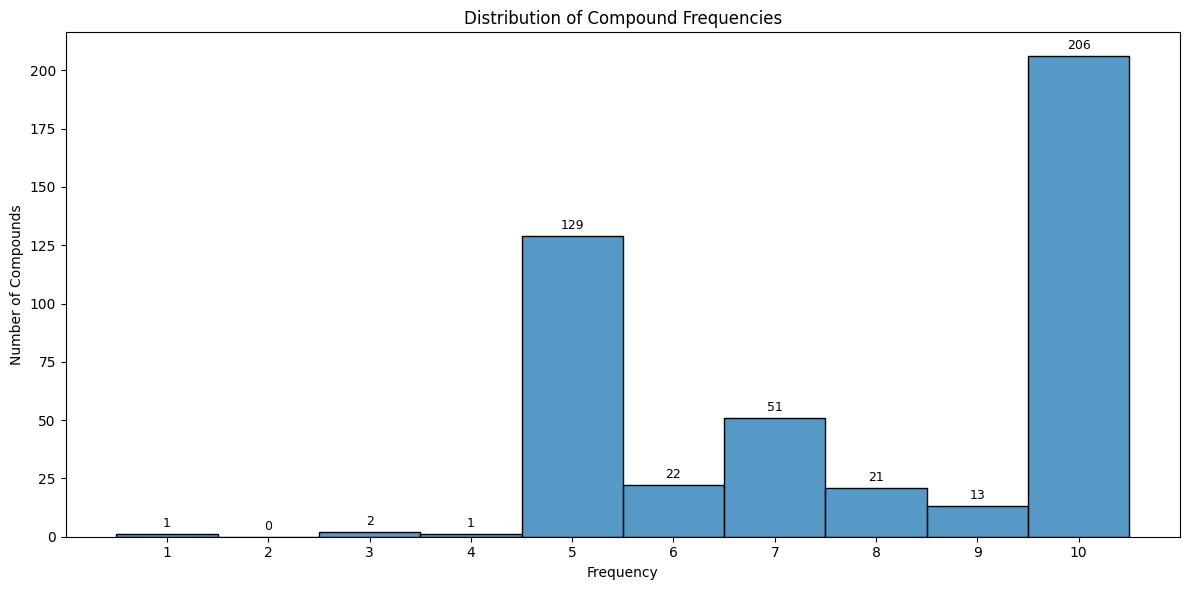

In [95]:
freq = df['Compound'].value_counts()

fig, ax = plt.subplots(figsize=(12, 6))

sns.histplot(freq, bins=10, discrete=True, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fontsize=9, padding=3)

ax.set_xticks(range(1, freq.max() + 1))
ax.set_xlabel('Frequency')
ax.set_ylabel('Number of Compounds')
ax.set_title('Distribution of Compound Frequencies')

plt.tight_layout()
plt.show()

## 7. Chia tập huấn luyện theo tần suất xuất hiện, tỷ lệ xấp xỉ 80/20 (Tổng 3490 = 2834 + 656)

In [ ]:
# freq = df['Compound'].value_counts()

# train_compounds = freq[freq >= 6].index
# valid_compounds = freq[freq < 6].index

# df_train = df[df['Compound'].isin(train_compounds)]
# df_valid = df[df['Compound'].isin(valid_compounds)]

# df_train.to_csv('../dataset/train/train.tsv', sep='\t', index=False)
# df_valid.to_csv('../dataset/valid/valid.tsv', sep='\t', index=False)